In [25]:
# Notebook initialization: imports and default definitions for analysis/runtime
import tensorflow as tf
import numpy as np
from tensorflow.keras import layers, models, applications
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, CSVLogger, ReduceLROnPlateau

# default hyperparameters (allow override by earlier cells)
img_width, img_height = globals().get('img_width', 128), globals().get('img_height', 128)
batch_size = globals().get('batch_size', 32)
epochs = globals().get('epochs', 120)

# placeholders so static analysis doesn't report undefined names
training_set = globals().get('training_set', None)
validation_set = globals().get('validation_set', None)
training_set_leaf = globals().get('training_set_leaf', None)
validation_set_leaf = globals().get('validation_set_leaf', None)

cnn = globals().get('cnn', None)
cnn_leaf = globals().get('cnn_leaf', None)
cnn_rambutan = globals().get('cnn_rambutan', None)

# print basic info
print(f"img_size={img_width}x{img_height}, batch_size={batch_size}, epochs={epochs}")

img_size=128x128, batch_size=32, epochs=120


## Dataset Preparation
- split
- directory

### Declare the directory

In [1]:
# ensure image size and batch size exist (won't overwrite if already set)
try:
    img_width, img_height
except NameError:
    img_width, img_height = (128, 128)

try:
    batch_size
except NameError:
    batch_size = 32

In [2]:
# Dataset path configuration
# Paths for leaf disease dataset (top-level disease folders)
# Binary classifier dataset (leaf vs fruit) built from the top-level train/val/test folders.
# It treats the immediate subfolders under ../train as classes; 'rambutan' (if present) is considered fruit.
import tensorflow as tf
import numpy as np

binary_train = tf.keras.utils.image_dataset_from_directory(
    '../train',
    labels='inferred',
    label_mode='int',
    batch_size=batch_size,
    image_size=(img_width,img_height),
    shuffle=True
)
binary_val = tf.keras.utils.image_dataset_from_directory(
    '../val',
    labels='inferred',
    label_mode='int',
    batch_size=batch_size,
    image_size=(img_width,img_height),
    shuffle=True
)

# Determine index of the 'rambutan' class among top-level folders (if present)
all_classes = binary_train.class_names
print('Top-level classes found:', all_classes)
fruit_index = None
if 'rambutan' in all_classes:
    fruit_index = all_classes.index('rambutan')
    print('Rambutan class index (fruit):', fruit_index)
else:
    print('No top-level folder found. Please ensure ../train/rambutan exists.')

# Map integer labels to binary labels: 1 for fruit (rambutan), 0 for leaf classes
def to_binary(x, y):
    if fruit_index is None:
        # fallback: treat any folder named 'rambutan' not found -> all as leaf (0)
        y_bin = tf.zeros_like(y)
    else:
        y_bin = tf.cast(tf.equal(y, fruit_index), tf.int32)
    return x, tf.one_hot(y_bin, depth=2)

binary_train = binary_train.map(to_binary)
binary_val = binary_val.map(to_binary)

# Small transfer-learning binary classifier (example)
from tensorflow.keras import layers, models, applications
base = applications.MobileNetV2(input_shape=(img_width,img_height,3), include_top=False, weights='imagenet')
base.trainable = False
model_bin = models.Sequential([
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(128, activation='relu'),
    layers.Dense(2, activation='softmax')
])
model_bin.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model_bin.summary()
# To train (uncomment):
# history_bin = model_bin.fit(binary_train, validation_data=binary_val, epochs=5)
# model_bin.save('model_binary_leaf_vs_fruit.keras')
# Inference helper: automatically route image to the correct model (leaf vs fruit)
from PIL import Image
import numpy as np

def preprocess_image(path, size=(img_width,img_height)):
    img = Image.open(path).convert('RGB')
    img = img.resize(size)
    arr = np.asarray(img).astype('float32') / 255.0
    return np.expand_dims(arr, 0)

# Load trained models if available (paths are examples)
# cnn_leaf = tf.keras.models.load_model('model_leaf.keras')
# cnn_rambutan = tf.keras.models.load_model('model_rambutan.keras')
# model_bin = tf.keras.models.load_model('model_binary_leaf_vs_fruit.keras')

# Thresholds: router confidence and specialist confidence below which we return 'unknown'
ROUTER_THRESHOLD = 0.6
SPECIALIST_THRESHOLD = 0.5

def auto_predict(image_path, use_auto_router=False, router_threshold=ROUTER_THRESHOLD, specialist_threshold=SPECIALIST_THRESHOLD):
    x = preprocess_image(image_path)
    # Decide whether image is fruit or leaf using binary router (optional)
    if use_auto_router:
        if 'model_bin' not in globals():
            return 'unknown', 'router_not_loaded', 0.0
        probs = model_bin.predict(x)[0]
        max_router_conf = float(np.max(probs))
        if max_router_conf < router_threshold:
            return 'unknown', 'router_low_conf', max_router_conf
        is_fruit = int(np.argmax(probs)) == 1
    else:
        # Default: assume leaf unless user specifies otherwise
        is_fruit = False

    # Call the appropriate specialist model and check confidence
    if is_fruit:
        if 'cnn_rambutan' not in globals():
            return 'unknown', 'rambutan_model_not_loaded', 0.0
        probs_r = cnn_rambutan.predict(x)[0]
        conf = float(np.max(probs_r))
        if conf < specialist_threshold:
            return 'unknown', 'rambutan_low_conf', conf
        label_idx = int(np.argmax(probs_r))
        return 'rambutan', rambutan_classes[label_idx], conf
    else:
        if 'cnn_leaf' not in globals():
            return 'unknown', 'leaf_model_not_loaded', 0.0
        probs_l = cnn_leaf.predict(x)[0]
        conf = float(np.max(probs_l))
        if conf < specialist_threshold:
            return 'unknown', 'leaf_low_conf', conf
        label_idx = int(np.argmax(probs_l))
        return 'leaf', leaf_classes[label_idx], conf

# Example usage (after training & saving models):
# result = auto_predict('sample.jpg', use_auto_router=True)
# print(result)
trainpath_leaf = '../train'
validpath_leaf = '../val'
testpath_leaf  = '../test'
# Specify the disease class names present in the train/ directory (exclude 'rambutan')
leaf_classes = ['Algal Leaf Spot','Anthracnose','Leaf Curl','Powdery Mildew','sooty mold']

# Paths for rambutan fruit ripeness dataset (nested ripeness folders)
trainpath_rambutan = '../train/rambutan'
validpath_rambutan = '../val/rambutan'
testpath_rambutan  = '../test/rambutan'
rambutan_classes = ['ripe','unripe','overripe']

# Note: This notebook will create separate datasets/models for leaves (disease) and rambutan (ripeness).

Found 2870 files belonging to 6 classes.
Found 2870 files belonging to 6 classes.
Top-level classes found: ['Algal Leaf Spot', 'Anthracnose', 'Leaf Curl', 'Powdery Mildew', 'rambutan', 'sooty mold']
Rambutan class index (fruit): 4


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,210 (9.24 MB)

 Trainable params: 164,226 (641.51 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### Set the Image Size

In [3]:
img_width, img_height = (128, 128)

In [ ]:
epochs = 120
batch_size = 32

: 

## Import Required Modules

`pip install tensorflow matplotlib pandas seaborn`


In [30]:

import tensorflow as tf
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

## Data Preprocessing and Augumentation    
Examples:   
- To balance the dataset and to increase the size of training and testing dataset
- Regularization technique to minimize overfitting
- Rescaling the image is Normalizing the image

In this notebook, I will not used any techniques for augmenting images since my datasets already augmented to avoid overfitting. The datasets was collected from different repositories, and already increase its size using data augmentation.

In [31]:
# Define dataset paths and verify contents
from pathlib import Path
trainpath = '../train'
validpath = '../val'
testpath  = '../test'
print('Notebook cwd:', Path.cwd())
for p in (trainpath, validpath, testpath):
    path = Path(p)
    print(p, 'exists:', path.exists())
    if path.exists():
        counts = {}
        for cls in [d for d in path.iterdir() if d.is_dir()]:
            files = list(cls.glob('**/*.jpg')) + list(cls.glob('**/*.jpeg')) + list(cls.glob('**/*.png'))
            counts[cls.name] = len(files)
        print('  counts:', counts)


Notebook cwd: c:\wamp64\www\Smart Farming System (1)\backend
../train exists: True
  counts: {'Algal Leaf Spot': 504, 'Anthracnose': 519, 'Leaf Curl': 482, 'Powdery Mildew': 366, 'rambutan': 251, 'sooty mold': 748}
../val exists: True
  counts: {'Algal Leaf Spot': 504, 'Anthracnose': 519, 'Leaf Curl': 482, 'Powdery Mildew': 366, 'rambutan': 251, 'sooty mold': 748}
../test exists: True
  counts: {'Algal Leaf Spot': 504, 'Anthracnose': 519, 'Leaf Curl': 482, 'Powdery Mildew': 366, 'rambutan': 251, 'sooty mold': 748}


In [32]:
training_set = tf.keras.utils.image_dataset_from_directory(
    trainpath,
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    color_mode="rgb",
    batch_size=batch_size,
    image_size=(img_width, img_height),
    shuffle=True,
    seed=None,
    validation_split=None,
    subset=None,
    interpolation="bilinear",
    follow_links=False,
    crop_to_aspect_ratio=False
)

Found 2870 files belonging to 6 classes.


In [36]:
# Create dataset loaders for leaf disease (uses top-level disease folders)
# Add data augmentation to improve model generalization
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.2),
    tf.keras.layers.RandomZoom(0.2),
    tf.keras.layers.RandomBrightness(0.2),
    tf.keras.layers.RandomContrast(0.2),
])

training_set_leaf = tf.keras.utils.image_dataset_from_directory(
    trainpath_leaf,
    labels="inferred",
    label_mode="categorical",
    class_names=leaf_classes,
    color_mode="rgb",
    batch_size=batch_size,
    image_size=(img_width, img_height),
    shuffle=True,
    interpolation="bilinear"
)

# Apply augmentation to training data only
training_set_leaf = training_set_leaf.map(lambda x, y: (data_augmentation(x, training=True), y))

validation_set_leaf = tf.keras.utils.image_dataset_from_directory(
    validpath_leaf,
    labels="inferred",
    label_mode="categorical",
    class_names=leaf_classes,
    color_mode="rgb",
    batch_size=batch_size,
    image_size=(img_width, img_height),
    shuffle=True,
    interpolation="bilinear"
)

Found 2619 files belonging to 5 classes.
Found 2619 files belonging to 5 classes.


In [37]:
# Create dataset loaders for rambutan ripeness (nested ripeness folders)
training_set_rambutan = tf.keras.utils.image_dataset_from_directory(
    trainpath_rambutan,
    labels="inferred",
    label_mode="categorical",
    class_names=rambutan_classes,
    color_mode="rgb",
    batch_size=batch_size,
    image_size=(img_width, img_height),
    shuffle=True,
    interpolation="bilinear"
)

validation_set_rambutan = tf.keras.utils.image_dataset_from_directory(
    validpath_rambutan,
    labels="inferred",
    label_mode="categorical",
    class_names=rambutan_classes,
    color_mode="rgb",
    batch_size=batch_size,
    image_size=(img_width, img_height),
    shuffle=True,
    interpolation="bilinear"
)

Found 251 files belonging to 3 classes.
Found 251 files belonging to 3 classes.


In [39]:
# Inspect dataset classes and image counts (helps verify ripeness folders)
import os
# Print class names inferred by the dataset loader
try:
    class_names = training_set.class_names
    print('Inferred class names:', class_names)
except Exception as e:
    print('Could not read class names from training_set:', e)

# Show file counts per class for train/val/test paths
for p in [trainpath, validpath, testpath]:
    print('\nContents of', p)
    if not os.path.exists(p):
        print('  Path does not exist:', p)
        continue
    for cls in sorted(os.listdir(p)):
        cls_path = os.path.join(p, cls)
        if os.path.isdir(cls_path):
            files = [f for f in os.listdir(cls_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
            print(f'  {cls}:', len(files))

Inferred class names: ['Algal Leaf Spot', 'Anthracnose', 'Leaf Curl', 'Powdery Mildew', 'rambutan', 'sooty mold']

Contents of ../train
  Algal Leaf Spot: 504
  Anthracnose: 519
  Leaf Curl: 482
  Powdery Mildew: 366
  rambutan: 0
  sooty mold: 748

Contents of ../val
  Algal Leaf Spot: 504
  Anthracnose: 519
  Leaf Curl: 482
  Powdery Mildew: 366
  rambutan: 0
  sooty mold: 748

Contents of ../test
  Algal Leaf Spot: 504
  Anthracnose: 519
  Leaf Curl: 482
  Powdery Mildew: 366
  rambutan: 0
  sooty mold: 748


In [40]:
validation_set = tf.keras.utils.image_dataset_from_directory(
    validpath,
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    color_mode="rgb",
    batch_size=batch_size,
    image_size=(img_width, img_height),
    shuffle=True,
    seed=None,
    validation_split=None,
    subset=None,
    interpolation="bilinear",
    follow_links=False,
    crop_to_aspect_ratio=False
)

Found 2870 files belonging to 6 classes.


## Transfer Learning
### Select Model

In [41]:
cnn = tf.keras.models.Sequential()

In [42]:
# Determine number of classes from available dataset loaders
try:
    num_classes = len(training_set.class_names)
except Exception:
    try:
        num_classes = len(training_set_leaf.class_names)
    except Exception:
        try:
            num_classes = len(rambutan_classes)
        except Exception:
            num_classes = 5

cnn.add(tf.keras.layers.Conv2D(filters=32, kernel_size=3, padding='same', activation='relu', input_shape=(img_width, img_height, 3)))
cnn.add(tf.keras.layers.Conv2D(filters=32,kernel_size=3,activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

cnn.add(tf.keras.layers.Conv2D(filters=64,kernel_size=3,padding='same',activation='relu'))
cnn.add(tf.keras.layers.Conv2D(filters=64,kernel_size=3,activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

cnn.add(tf.keras.layers.Conv2D(filters=128,kernel_size=3,padding='same',activation='relu'))
cnn.add(tf.keras.layers.Conv2D(filters=128,kernel_size=3,activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

cnn.add(tf.keras.layers.Conv2D(filters=256,kernel_size=3,padding='same',activation='relu'))
cnn.add(tf.keras.layers.Conv2D(filters=256,kernel_size=3,activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

cnn.add(tf.keras.layers.Conv2D(filters=512,kernel_size=3,padding='same',activation='relu'))
cnn.add(tf.keras.layers.Conv2D(filters=512,kernel_size=3,activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

cnn.add(tf.keras.layers.Dropout(0.25))

cnn.add(tf.keras.layers.Flatten())

cnn.add(tf.keras.layers.Dense(units=1658,activation='relu'))

cnn.add(tf.keras.layers.Dropout(0.4)) #To avoid overfitting

# Output Layer: match dataset class count
cnn.add(tf.keras.layers.Dense(units=num_classes, activation='softmax'))

In [43]:
cnn.compile(optimizer=tf.keras.optimizers.Adam(
    learning_rate=0.0001),loss='categorical_crossentropy',metrics=['accuracy'])

In [ ]:
cnn.summary()

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_23 (Conv2D)              │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_24 (Conv2D)              │ (None, 126, 126, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_25 (Conv2D)              │ (None, 63, 63, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_26 (Conv2D)              │ (None, 61, 61, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_27 (Conv2D)              │ (None, 30, 30, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_28 (Conv2D)              │ (None, 28, 28, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_29 (Conv2D)              │ (None, 14, 14, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_30 (Conv2D)              │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_31 (Conv2D)              │ (None, 6, 6, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_32 (Conv2D)              │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 2, 2, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 2, 2, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1658)           │     3,397,242 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 1658)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 6)              │         9,954 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,119,420 (30.97 MB)

 Trainable params: 8,119,420 (30.97 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
# ===== RETRAIN LEAF DISEASE MODEL WITH BATCH NORMALIZATION =====
import gc
# Clear memory if cnn exists
try:
    del cnn
except:
    pass
gc.collect()

cnn_leaf_disease = tf.keras.models.Sequential()

# Layer 1: Conv + BatchNorm + Conv + BatchNorm + Pool
cnn_leaf_disease.add(tf.keras.layers.Conv2D(filters=32, kernel_size=3, padding='same', activation='relu', input_shape=(img_width, img_height, 3)))
cnn_leaf_disease.add(tf.keras.layers.BatchNormalization())
cnn_leaf_disease.add(tf.keras.layers.Conv2D(filters=32, kernel_size=3, activation='relu'))
cnn_leaf_disease.add(tf.keras.layers.BatchNormalization())
cnn_leaf_disease.add(tf.keras.layers.MaxPool2D(pool_size=2, strides=2))

# Layer 2
cnn_leaf_disease.add(tf.keras.layers.Conv2D(filters=64, kernel_size=3, padding='same', activation='relu'))
cnn_leaf_disease.add(tf.keras.layers.BatchNormalization())
cnn_leaf_disease.add(tf.keras.layers.Conv2D(filters=64, kernel_size=3, activation='relu'))
cnn_leaf_disease.add(tf.keras.layers.BatchNormalization())
cnn_leaf_disease.add(tf.keras.layers.MaxPool2D(pool_size=2, strides=2))

# Layer 3
cnn_leaf_disease.add(tf.keras.layers.Conv2D(filters=128, kernel_size=3, padding='same', activation='relu'))
cnn_leaf_disease.add(tf.keras.layers.BatchNormalization())
cnn_leaf_disease.add(tf.keras.layers.Conv2D(filters=128, kernel_size=3, activation='relu'))
cnn_leaf_disease.add(tf.keras.layers.BatchNormalization())
cnn_leaf_disease.add(tf.keras.layers.MaxPool2D(pool_size=2, strides=2))

# Layer 4
cnn_leaf_disease.add(tf.keras.layers.Conv2D(filters=256, kernel_size=3, padding='same', activation='relu'))
cnn_leaf_disease.add(tf.keras.layers.BatchNormalization())
cnn_leaf_disease.add(tf.keras.layers.Conv2D(filters=256, kernel_size=3, activation='relu'))
cnn_leaf_disease.add(tf.keras.layers.BatchNormalization())
cnn_leaf_disease.add(tf.keras.layers.MaxPool2D(pool_size=2, strides=2))

# Layer 5
cnn_leaf_disease.add(tf.keras.layers.Conv2D(filters=512, kernel_size=3, padding='same', activation='relu'))
cnn_leaf_disease.add(tf.keras.layers.BatchNormalization())
cnn_leaf_disease.add(tf.keras.layers.Conv2D(filters=512, kernel_size=3, activation='relu'))
cnn_leaf_disease.add(tf.keras.layers.BatchNormalization())
cnn_leaf_disease.add(tf.keras.layers.MaxPool2D(pool_size=2, strides=2))

# Fully Connected Layers with stronger regularization
cnn_leaf_disease.add(tf.keras.layers.Dropout(0.35))
cnn_leaf_disease.add(tf.keras.layers.Flatten())
cnn_leaf_disease.add(tf.keras.layers.Dense(units=1280, activation='relu'))
cnn_leaf_disease.add(tf.keras.layers.BatchNormalization())
cnn_leaf_disease.add(tf.keras.layers.Dropout(0.5))

# Output: 5 disease classes
cnn_leaf_disease.add(tf.keras.layers.Dense(units=5, activation='softmax'))

# Compile with very low learning rate
cnn_leaf_disease.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00002),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("✅ Model built for leaf disease detection (5 classes)")
print(f"Classes: {leaf_classes}")
cnn_leaf_disease.summary()

✅ Model built for leaf disease detection (5 classes)
Classes: ['Algal Leaf Spot', 'Anthracnose', 'Leaf Curl', 'Powdery Mildew', 'sooty mold']


Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_33 (Conv2D)              │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_34 (Conv2D)              │ (None, 126, 126, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 126, 126, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_35 (Conv2D)              │ (None, 63, 63, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 63, 63, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_36 (Conv2D)              │ (None, 61, 61, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 61, 61, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_37 (Conv2D)              │ (None, 30, 30, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 30, 30, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_38 (Conv2D)              │ (None, 28, 28, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_39 (Conv2D)              │ (None, 14, 14, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 14, 14, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_40 (Conv2D)              │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 12, 12, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_41 (Conv2D)              │ (None, 6, 6, 512)      │     1,180,16

 Total params: 7,354,405 (28.05 MB)

 Trainable params: 7,347,877 (28.03 MB)

 Non-trainable params: 6,528 (25.50 KB)

In [19]:
# Train the leaf disease model with enhanced callbacks
print("Training leaf disease model with augmentation and regularization...")
print(f"Training samples: {len(training_set_leaf)}, Validation samples: {len(validation_set_leaf)}")

from tensorflow.keras.callbacks import ModelCheckpoint, CSVLogger, EarlyStopping, ReduceLROnPlateau

# Callbacks for optimal training
checkpoint = ModelCheckpoint('model_leaf_disease_checkpoint.keras', save_best_only=True, save_weights_only=False, monitor='val_accuracy')
csv_logger = CSVLogger('training_leaf_disease_log.csv', append=False)
early_stop = EarlyStopping(monitor='val_loss', patience=150, restore_best_weights=True, verbose=1)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=20, min_lr=0.000001, verbose=1)

# Train for up to 200 epochs with callbacks
num_epochs = 200
training_history_leaf = cnn_leaf_disease.fit(
    x=training_set_leaf,
    validation_data=validation_set_leaf,
    epochs=num_epochs,
    callbacks=[checkpoint, csv_logger, early_stop, reduce_lr],
    verbose=1
)

print("\n✅ Training complete!")
print(f"Final training accuracy: {training_history_leaf.history['accuracy'][-1]:.4f}")
print(f"Final validation accuracy: {training_history_leaf.history['val_accuracy'][-1]:.4f}")
print(f"Training loss: {training_history_leaf.history['loss'][-1]:.4f}")
print(f"Validation loss: {training_history_leaf.history['val_loss'][-1]:.4f}")

Training leaf disease model with augmentation and regularization...
Training samples: 82, Validation samples: 82
Epoch 1/200


82/82 ━━━━━━━━━━━━━━━━━━━━ 206s 2s/step - accuracy: 0.4147 - loss: 1.8262 - val_accuracy: 0.2684 - val_loss: 1.6578 - learning_rate: 2.0000e-05
Epoch 2/200
82/82 ━━━━━━━━━━━━━━━━━━━━ 188s 2s/step - accuracy: 0.5918 - loss: 1.2375 - val_accuracy: 0.4292 - val_loss: 1.3360 - learning_rate: 2.0000e-05
Epoch 3/200
82/82 ━━━━━━━━━━━━━━━━━━━━ 186s 2s/step - accuracy: 0.6304 - loss: 1.1514 - val_accuracy: 0.6564 - val_loss: 0.9535 - learning_rate: 2.0000e-05
Epoch 4/200
82/82 ━━━━━━━━━━━━━━━━━━━━ 187s 2s/step - accuracy: 0.6544 - loss: 1.0933 - val_accuracy: 0.7289 - val_loss: 0.7695 - learning_rate: 2.0000e-05
Epoch 5/200
82/82 ━━━━━━━━━━━━━━━━━━━━ 185s 2s/step - accuracy: 0.6800 - loss: 0.9828 - val_accuracy: 0.7064 - val_loss: 0.7333 - learning_rate: 2.0000e-05
Epoch 6/200
82/82 ━━━━━━━━━━━━━━━━━━━━ 192s 2s/step - accuracy: 0.7163 - loss: 0.8601 - val_accuracy: 0.7171 - val_loss: 0.7761 - learning_rate: 2.0000e-05
Epoch 7/200
82/82 ━━━━━━━━━━━━━━━━━━━━ 188s 2s/step - accuracy: 0.7216 - los

## Training Process

In [1]:
# ensure tensorflow is available when running this cell standalone
import tensorflow as tf

# Safe defaults when this cell is run out of notebook order
batch_size = globals().get('batch_size', 32)
img_width = globals().get('img_width', 128)
img_height = globals().get('img_height', 128)
epochs = globals().get('epochs', 120)

# Ensure model `cnn` exists before training
if 'cnn' not in globals():
    try:
        # try loading from saved checkpoint
        cnn = tf.keras.models.load_model('model_checkpoint.keras')
        print('Loaded cnn from checkpoint.')
    except Exception as e:
        print('cnn not defined and no checkpoint found, rebuilding architecture.')
        # rebuild simple cnn architecture used earlier
        cnn = tf.keras.models.Sequential()
        cnn.add(tf.keras.layers.Conv2D(filters=32, kernel_size=3, padding='same', activation='relu', input_shape=(img_width, img_height, 3)))
        cnn.add(tf.keras.layers.Conv2D(filters=32,kernel_size=3,activation='relu'))
        cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))
        cnn.add(tf.keras.layers.Conv2D(filters=64,kernel_size=3,padding='same',activation='relu'))
        cnn.add(tf.keras.layers.Conv2D(filters=64,kernel_size=3,activation='relu'))
        cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))
        cnn.add(tf.keras.layers.Conv2D(filters=128,kernel_size=3,padding='same',activation='relu'))
        cnn.add(tf.keras.layers.Conv2D(filters=128,kernel_size=3,activation='relu'))
        cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))
        cnn.add(tf.keras.layers.Conv2D(filters=256,kernel_size=3,padding='same',activation='relu'))
        cnn.add(tf.keras.layers.Conv2D(filters=256,kernel_size=3,activation='relu'))
        cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))
        cnn.add(tf.keras.layers.Conv2D(filters=512,kernel_size=3,padding='same',activation='relu'))
        cnn.add(tf.keras.layers.Conv2D(filters=512,kernel_size=3,activation='relu'))
        cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))
        cnn.add(tf.keras.layers.Dropout(0.25))
        cnn.add(tf.keras.layers.Flatten())
        cnn.add(tf.keras.layers.Dense(units=1658,activation='relu'))
        cnn.add(tf.keras.layers.Dropout(0.4))
        cnn.add(tf.keras.layers.Dense(units=num_classes, activation='softmax'))
        cnn.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
                    loss='categorical_crossentropy', metrics=['accuracy'])
        print('Rebuilt cnn model.')

# Ensure train/validation datasets exist
if 'training_set' not in globals() or training_set is None:
    train_dir = globals().get('trainpath', '../train')
    training_set = tf.keras.utils.image_dataset_from_directory(
        train_dir,
        labels="inferred",
        label_mode="categorical",
        batch_size=batch_size,
        image_size=(img_width, img_height),
        shuffle=True
    )
    print("Created `training_set` from", train_dir)

if 'validation_set' not in globals() or validation_set is None:
    val_dir = globals().get('validpath', '../val')
    validation_set = tf.keras.utils.image_dataset_from_directory(
        val_dir,
        labels="inferred",
        label_mode="categorical",
        batch_size=batch_size,
        image_size=(img_width, img_height),
        shuffle=True
    )
    print("Created `validation_set` from", val_dir)

# Ensure callbacks exist
if 'checkpoint' not in globals():
    checkpoint = tf.keras.callbacks.ModelCheckpoint(
        'model_checkpoint.keras', save_best_only=True, monitor='val_accuracy'
    )
if 'csv_logger' not in globals():
    csv_logger = tf.keras.callbacks.CSVLogger('training_log.csv', append=False)

# Create EarlyStopping with patience equal to target epochs so it will not stop early
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=epochs, restore_best_weights=True
)

training_history = cnn.fit(
    x=training_set,
    validation_data=validation_set,
    epochs=epochs,
    callbacks=[checkpoint, csv_logger, early_stop]
)

Loaded cnn from checkpoint.
Found 2870 files belonging to 6 classes.
Created `training_set` from ../train
Found 2870 files belonging to 6 classes.
Created `validation_set` from ../val
Epoch 1/120
90/90 ━━━━━━━━━━━━━━━━━━━━ 179s 2s/step - accuracy: 0.9589 - loss: 0.1205 - val_accuracy: 0.9770 - val_loss: 0.0481
Epoch 2/120
90/90 ━━━━━━━━━━━━━━━━━━━━ 179s 2s/step - accuracy: 0.9700 - loss: 0.0874 - val_accuracy: 0.9498 - val_loss: 0.1241
Epoch 3/120
90/90 ━━━━━━━━━━━━━━━━━━━━ 180s 2s/step - accuracy: 0.9791 - loss: 0.0591 - val_accuracy: 0.9798 - val_loss: 0.0392
Epoch 4/120
90/90 ━━━━━━━━━━━━━━━━━━━━ 171s 2s/step - accuracy: 0.9774 - loss: 0.0467 - val_accuracy: 0.9805 - val_loss: 0.0429
Epoch 5/120
90/90 ━━━━━━━━━━━━━━━━━━━━ 173s 2s/step - accuracy: 0.9794 - loss: 0.0427 - val_accuracy: 0.9819 - val_loss: 0.0372
Epoch 6/120
90/90 ━━━━━━━━━━━━━━━━━━━━ 168s 2s/step - accuracy: 0.9815 - loss: 0.0396 - val_accuracy: 0.9801 - val_loss: 0.0373
Epoch 7/120
90/90 ━━━━━━━━━━━━━━━━━━━━ 169s 2s/s

In [2]:
# Resume training from the saved full-model checkpoint
from tensorflow.keras.models import load_model
# Load the model saved by ModelCheckpoint (full model)
cnn = load_model('model_checkpoint.keras')
# Determine the last completed epoch (use CSV log or previous history). Example: 118
last_completed_epoch = 118
total_epochs = 120
# Continue training; training resumes at last_completed_epoch+1
cnn.fit(x=training_set, validation_data=validation_set, epochs=total_epochs, initial_epoch=last_completed_epoch, callbacks=[checkpoint, csv_logger, early_stop])

# If you only saved weights, rebuild the model architecture then:
# cnn = build_model()  # your model builder code
# cnn.load_weights('model_weights.h5')
# cnn.fit(..., initial_epoch=last_completed_epoch, ...)

Epoch 119/120
90/90 ━━━━━━━━━━━━━━━━━━━━ 162s 2s/step - accuracy: 0.9801 - loss: 0.0403 - val_accuracy: 0.9822 - val_loss: 0.0365
Epoch 120/120
90/90 ━━━━━━━━━━━━━━━━━━━━ 168s 2s/step - accuracy: 0.9812 - loss: 0.0394 - val_accuracy: 0.9819 - val_loss: 0.0367


## Training Accuracy

In [25]:
#Training set Accuracy
train_loss, train_acc = cnn.evaluate(training_set)
print('Training accuracy:', train_acc)

90/90 ━━━━━━━━━━━━━━━━━━━━ 47s 522ms/step - accuracy: 0.9822 - loss: 0.0365
Training accuracy: 0.9822299480438232


## Validation Accuracy

In [26]:
#Validation set Accuracy
val_loss, val_acc = cnn.evaluate(validation_set)
print('Validation accuracy:', val_acc)

90/90 ━━━━━━━━━━━━━━━━━━━━ 41s 448ms/step - accuracy: 0.9822 - loss: 0.0365
Validation accuracy: 0.9822299480438232


## Save the Model in Keras format

In [27]:
# Ensure target directories exist before saving
import os
os.makedirs('modelkeras', exist_ok=True)
cnn.save('modelkeras/trained_corn_disease_model.keras')

In [28]:
#Recording History in json
import json
with open('modelkeras/training_corn_hist.json','w') as f:
  json.dump(training_history.history,f)

## Save the Model in h5 format

In [29]:
# Ensure HDF5 directory exists before saving
import os
os.makedirs('modelh5', exist_ok=True)
cnn.save('modelh5/trained_corn_disease_model.h5')

In [30]:
#Recording History in json
import json
with open('modelh5/training_corn_hist.json','w') as f:
  json.dump(training_history.history,f)

## Model History

In [31]:
training_history.history #Return Dictionary of history

{'accuracy': [0.9588850140571594,
  0.9700348377227783,
  0.9790940880775452,
  0.9773519039154053,
  0.9794425368309021,
  0.9815331101417542,
  0.9794425368309021,
  0.9825783967971802,
  0.9797909259796143,
  0.9801393747329712,
  0.9815331101417542,
  0.9808362126350403,
  0.9811846613883972,
  0.9818815588951111,
  0.9811846613883972,
  0.9818815588951111,
  0.9818815588951111,
  0.9804878234863281,
  0.9818815588951111,
  0.9822299480438232,
  0.9804878234863281,
  0.9818815588951111,
  0.9815331101417542,
  0.9794425368309021,
  0.9825783967971802,
  0.9822299480438232,
  0.9811846613883972,
  0.9815331101417542,
  0.9811846613883972,
  0.9801393747329712,
  0.9815331101417542,
  0.9797909259796143,
  0.9822299480438232,
  0.9818815588951111,
  0.9822299480438232,
  0.9811846613883972,
  0.9829268455505371,
  0.9801393747329712,
  0.9804878234863281,
  0.9822299480438232,
  0.9815331101417542,
  0.9815331101417542,
  0.9825783967971802,
  0.9811846613883972,
  0.9808362126350403

In [32]:
print(training_history.history.keys())

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


In [33]:
training_accuracy      = training_history.history['accuracy'][-1]
training_loss          = training_history.history['loss'][-1]
validation_accuracy    = training_history.history['val_accuracy'][-1]
validation_loss       = training_history.history['val_loss'][-1]
print("Training Accuracy   :", training_accuracy )
print("Training Loss       :", training_loss)
print("Validation Accuracy :", validation_accuracy)
print("Validation Loss     :", validation_loss)

Training Accuracy   : 0.9825783967971802
Training Loss       : 0.03790034353733063
Validation Accuracy : 0.9822299480438232
Validation Loss     : 0.03617282584309578


## Visualization

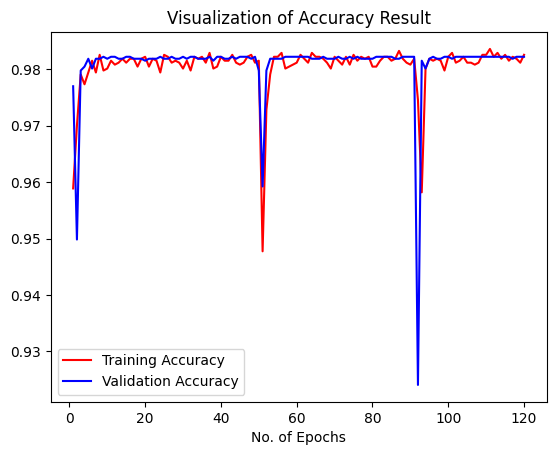

In [53]:
# Plot training/validation accuracy using actual history length
import matplotlib.pyplot as plt
train_acc = training_history.history.get('accuracy', [])
val_acc = training_history.history.get('val_accuracy', [])
# use a different name so we don't overwrite the integer `epochs` variable used for training
epoch_range = list(range(1, max(len(train_acc), len(val_acc)) + 1))
if train_acc:
    plt.plot(epoch_range[:len(train_acc)], train_acc, color='red', label='Training Accuracy')
if val_acc:
    plt.plot(epoch_range[:len(val_acc)], val_acc, color='blue', label='Validation Accuracy')
plt.xlabel('No. of Epochs')
plt.title('Visualization of Accuracy Result')
plt.legend()
plt.show()

In [54]:
class_name = validation_set.class_names

In [55]:
class_name

['Algal Leaf Spot',
 'Anthracnose',
 'Leaf Curl',
 'Powdery Mildew',
 'rambutan',
 'sooty mold']

## Test

In [58]:
testpath = globals().get('testpath', '../test')
batch_size = globals().get('batch_size', 32)
img_width = globals().get('img_width', 128)
img_height = globals().get('img_height', 128)

test_set = tf.keras.utils.image_dataset_from_directory(
    directory=testpath,
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    color_mode="rgb",
    batch_size=batch_size,
    image_size=(img_width, img_height),
    shuffle=False,
    seed=None,
    validation_split=None,
    subset=None,
    interpolation="bilinear",
    follow_links=False,
    crop_to_aspect_ratio=False
)


Found 2870 files belonging to 6 classes.


In [60]:
y_pred = cnn.predict(test_set)
predicted_categories = tf.argmax(y_pred, axis=1)

90/90 ━━━━━━━━━━━━━━━━━━━━ 48s 530ms/step


In [61]:
true_categories = tf.concat([y for x, y in test_set], axis=0)
Y_true = tf.argmax(true_categories, axis=1)

In [62]:
Y_true

<tf.Tensor: shape=(2870,), dtype=int64, numpy=array([0, 0, 0, ..., 5, 5, 5], shape=(2870,))>

In [63]:
predicted_categories

<tf.Tensor: shape=(2870,), dtype=int64, numpy=array([0, 0, 0, ..., 5, 5, 5], shape=(2870,))>

## Model Evaluation

In [64]:
from sklearn.metrics import confusion_matrix,classification_report
cm = confusion_matrix(Y_true,predicted_categories)

In [80]:
# Precision Recall Fscore
print(classification_report(Y_true,predicted_categories,target_names=class_name))

                 precision    recall  f1-score   support

Algal Leaf Spot       1.00      1.00      1.00       504
    Anthracnose       1.00      0.91      0.95       519
      Leaf Curl       0.92      1.00      0.96       482
 Powdery Mildew       0.99      0.99      0.99       366
       rambutan       1.00      1.00      1.00       251
     sooty mold       0.99      1.00      1.00       748

       accuracy                           0.98      2870
      macro avg       0.98      0.98      0.98      2870
   weighted avg       0.98      0.98      0.98      2870



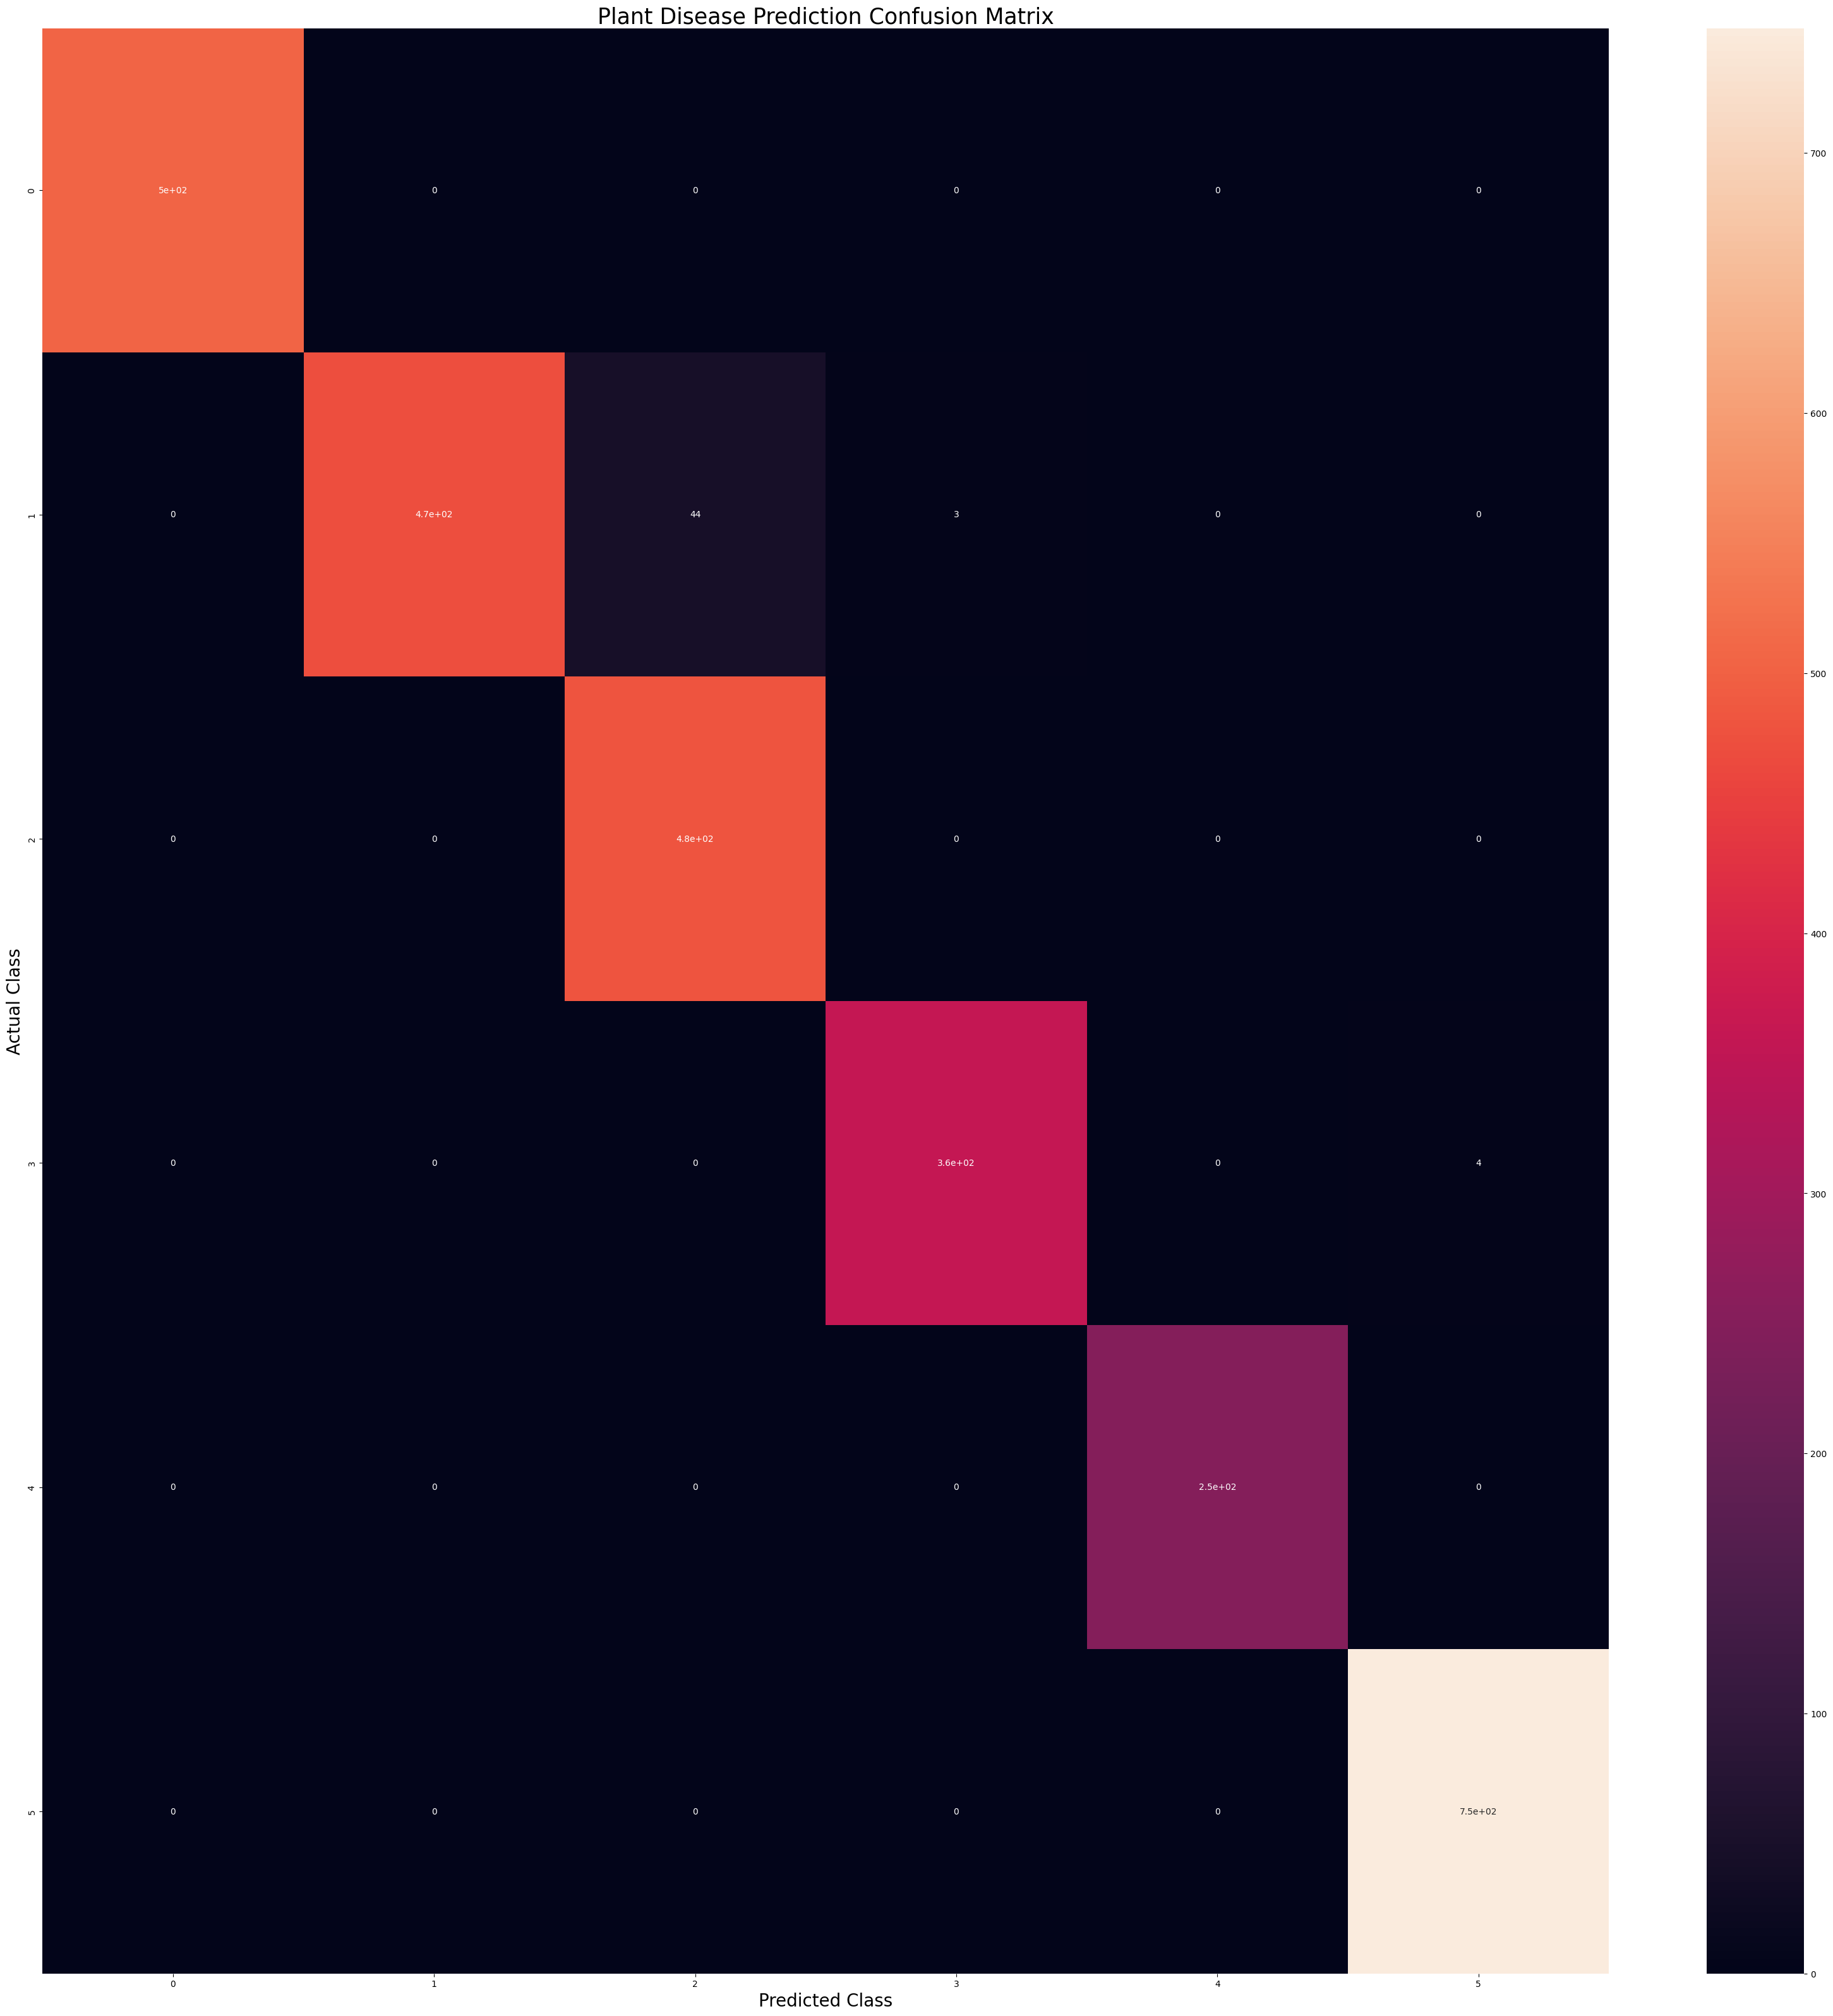

In [81]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(40, 40))
sns.heatmap(cm,annot=True,annot_kws={"size": 10})

plt.xlabel('Predicted Class',fontsize = 20)
plt.ylabel('Actual Class',fontsize = 20)
plt.title('Plant Disease Prediction Confusion Matrix',fontsize = 25)
plt.show()

# Deploy the Model

load model

In [82]:
cnn_corn = tf.keras.models.load_model('modelkeras/trained_corn_disease_model.keras')

c:\wamp64\www\Smart Farming System (1)\.venv\Lib\site-packages\keras\src\saving\saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'rmsprop', because it has 26 variables whereas the saved optimizer has 50 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


load image

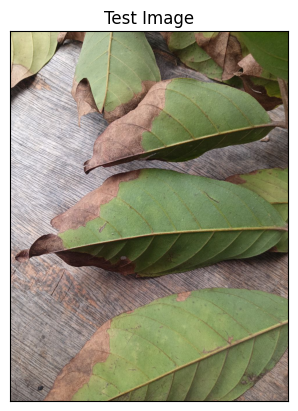

In [83]:
#Test Image Visualization
import cv2
image_path = '../val/Anthracnose/Anthracnose  (18).jpg'
# Reading an image in default mode
img = cv2.imread(image_path)
img = cv2.cvtColor(img,cv2.COLOR_BGR2RGB) #Converting BGR to RGB
# Displaying the image 
plt.imshow(img)
plt.title('Test Image')
plt.xticks([])
plt.yticks([])
plt.show()

preprocess image

In [84]:
#image = tf.keras.preprocessing.image.load_img(image_path,target_size=(128,128))
#input_arr = tf.keras.preprocessing.image.img_to_array(image)

import numpy as np
from PIL import Image
from numpy import asarray

# Load the image
img = Image.open(image_path)

# Resize the image
resized_img = img.resize((128, 128))

# Convert to a NumPy array
numpydata = asarray(resized_img)

input_arr = np.array([numpydata])  # Convert single image to a batch.


Predict

In [85]:
predictions = cnn_corn.predict(input_arr)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 402ms/step


In [86]:
print(predictions)

[[1.4733412e-05 9.9882025e-01 5.8097619e-04 1.8450600e-04 3.2804729e-04
  7.1408867e-05]]


In [87]:
result_index = np.argmax(predictions) #Return index of max element
print(result_index)

1


In [88]:
print(class_name)

['Algal Leaf Spot', 'Anthracnose', 'Leaf Curl', 'Powdery Mildew', 'rambutan', 'sooty mold']


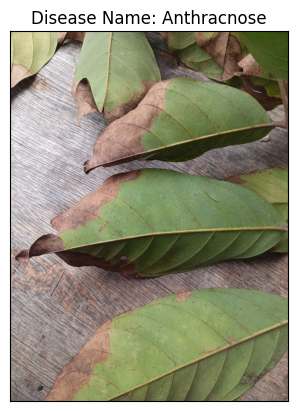

In [89]:
# Displaying the disease prediction
model_prediction = class_name[result_index]
plt.imshow(img)
plt.title(f"Disease Name: {model_prediction}")
plt.xticks([])
plt.yticks([])
plt.show()

## Other way to save the model

In [ ]:
# Save model weights to HDF5 file
cnn_corn.save_weights("modeljs/model_weights.weights.h5")
